Enter measurement (00, 01, 10, 11):  01


Bob applies: X gate

Alice's input:
0.6 0.8

Bob's output:
(0.6+0j) (0.8000000000000002+0j)

Fidelity: 1.0
Teleportation successful!


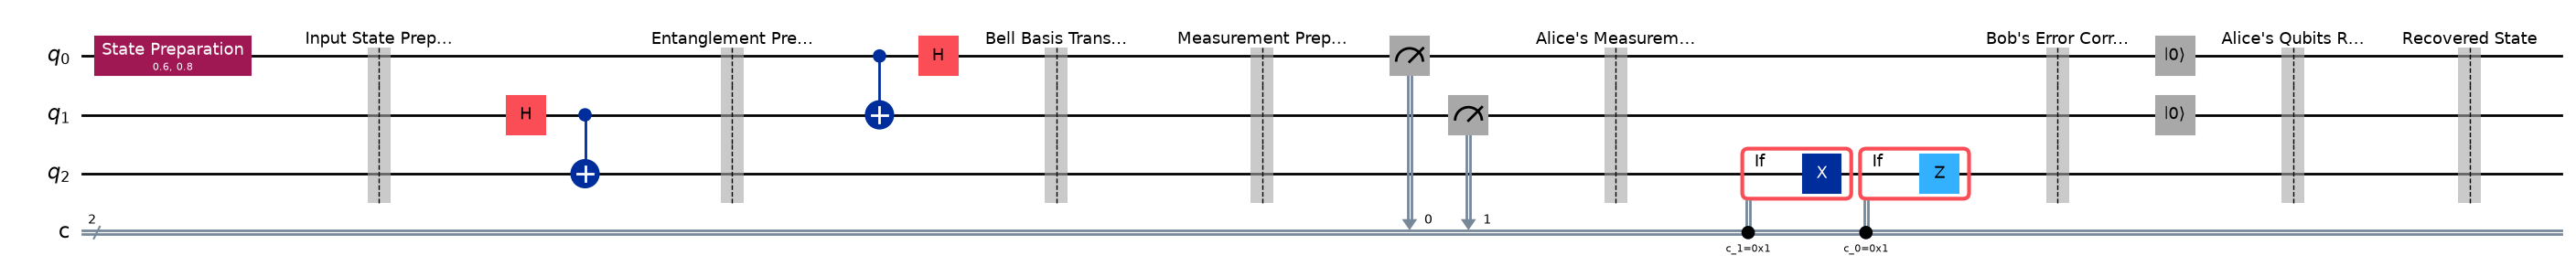

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
import numpy as np


# 1. Create circuit
q = QuantumRegister(3, 'q')
qc = QuantumCircuit(q)

# 2. Alice's input state
alpha, beta = 0.6, 0.8

qc.prepare_state([alpha, beta], q[0])
qc.barrier(label="Input State Preparation")

# 3. Create Bell pair
qc.h(q[1])
qc.cx(q[1], q[2])
qc.barrier(label="Entanglement Preparation")

# 4. Alice's operations
qc.cx(q[0], q[1])
qc.h(q[0])
qc.barrier(label="Bell Basis Transformation")

# 5. Statevector before measurement
sv = Statevector(qc)

# 6. Alice's measurement result
result = input("Enter measurement (00, 01, 10, 11): ")

if result not in ["00", "01", "10", "11"]:
    raise ValueError("Enter a valid 2-bit measurement.")

m0, m1 = int(result[0]), int(result[1])

# 7. Extract Bob's state
base = m0 + 2*m1

bob_alpha = sv.data[base]
bob_beta = sv.data[base + 4]

norm = np.sqrt(abs(bob_alpha)**2 + abs(bob_beta)**2)

bob_alpha /= norm
bob_beta /= norm

# 8. Bob's corrections
if m1 == 1:
    print("Bob applies: X gate")
    bob_alpha, bob_beta = bob_beta, bob_alpha

if m0 == 1:
    print("Bob applies: Z gate")
    bob_beta = -bob_beta

if m0 == 0 and m1 == 0:
    print("Bob applies: No operation")

# 9. Display output
print("\nAlice's input:")
print(alpha, beta)

print("\nBob's output:")
print(bob_alpha, bob_beta)

# 10. Verify teleportation
fidelity = abs(alpha.conjugate()*bob_alpha +
               beta.conjugate()*bob_beta)**2

print("\nFidelity:", fidelity)

if abs(fidelity - 1) < 1e-10:
    print("Teleportation successful!")
else:
    print("Teleportation unsuccessful.")

# 11. Add measurements and corrections to circuit

c = ClassicalRegister(2, 'c')
qc.add_register(c)

qc.barrier(label="Measurement Preparation")

qc.measure(q[0], c[0])
qc.measure(q[1], c[1])

qc.barrier(label="Alice's Measurement Results")

# Bob's corrections

with qc.if_test((c[1], 1)):
    qc.x(q[2])

with qc.if_test((c[0], 1)):
    qc.z(q[2])

qc.barrier(label="Bob's Error Correction")


# 12. Reset Alice's unused qubits

qc.reset(q[0])
qc.reset(q[1])


# After teleportation:
# - q[0] and q[1] are measured and no longer needed.
# - q[2] contains Bob's recovered quantum state.
# reseting q[2], would destroy Bob's teleported state.

qc.barrier(label="Alice's Qubits Reset - Available for Reuse")


# 13. Preserve Bob's recovered state

qc.barrier(label="Recovered State")


# 14. Draw circuit

qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("1_Teleportation.png", dpi=300, bbox_inches="tight")